<!-- project-navigation -->
# 16_SHAP_Interpretation
Role: Model explanation.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


1. Comment lire ton graphique

Pour chaque variable :

Rouge = valeur élevée
Bleu = valeur faible
À droite de 0 = contribution qui augmente la prédiction de défaut
À gauche de 0 = contribution qui diminue la prédiction de défaut
Plus les points sont éloignés de 0, plus l'effet est important.

⚠️ Petite précision importante : avec TreeExplainer, selon la configuration du modèle, les SHAP peuvent représenter l'impact sur la sortie du modèle (souvent l'échelle log-odds pour un classifieur LightGBM), et pas directement une variation de probabilité en %. Donc on parle ici de contribution à la prédiction de défaut, pas de « +10 % de probabilité ».

2. 🔥 Les 3 variables les plus importantes
EXT_SOURCE_2

C'est clairement la variable dominante.

Sur ton graphique :

🔴 valeurs élevées → principalement à gauche
🔵 valeurs faibles → principalement à droite

Donc :

Une valeur élevée de EXT_SOURCE_2 tend à réduire le risque de défaut prédit, tandis qu'une valeur faible tend à augmenter le risque de défaut.

C'est une relation très nette.

EXT_SOURCE_3

Même comportement :

valeurs élevées → gauche → diminution du risque
valeurs faibles → droite → augmentation du risque

Donc :

Les faibles scores EXT_SOURCE_3 sont associés à une contribution plus importante au risque de défaut.

EXT_SOURCE_1

Encore une fois, même tendance :

🔴 élevé → plutôt à gauche
🔵 faible → plutôt à droite

Donc les trois variables externes ont une relation cohérente :

Plus les indicateurs externes de solvabilité sont faibles, plus le modèle tend à prédire un risque de défaut élevé.

C'est probablement la conclusion la plus importante de ton analyse SHAP.

3. CODE_GENDER ⚠️

Ici :

bleu → plutôt à gauche
rouge → plutôt à droite

Donc certaines valeurs de CODE_GENDER sont associées à une contribution plus élevée au risque.

Mais on ne peut pas encore dire "homme → risque élevé" ou "femme → risque élevé".

Pourquoi ?

Parce que CODE_GENDER a été encodée numériquement. Il faut savoir quelle valeur correspond à quel sexe dans ton preprocessing.

Par exemple, si ton encodage était :

F = 0
M = 1

alors l'interprétation serait différente de :

F = 1
M = 0

Donc pour cette variable, ne mets pas encore de conclusion dans ta présentation avant de vérifier l'encodage.

Et pour un projet de Credit Risk, il est également pertinent de signaler que cette variable socio-démographique doit être interprétée avec prudence du point de vue de l'équité.

4. LATE_PAYMENT_RATIO ⭐

Ici le résultat est très intéressant.

On observe :

🔵 faibles valeurs → proche de 0 / légèrement à gauche
🔴 valeurs élevées → clairement à droite

Donc :

Plus la proportion de paiements en retard est élevée, plus elle contribue à augmenter le risque de défaut prédit.

C'est une relation très intuitive du point de vue métier.

Et c'est une variable créée par ton feature engineering, donc c'est particulièrement intéressant à présenter.

Tu peux expliquer :

LATE_PAYMENT_RATIO mesure la proportion de paiements présentant un retard dans l'historique du client. Son importance élevée montre que le comportement de remboursement passé constitue un signal important pour l'évaluation du risque.

5. AVG_CNT_INSTALMENT_FUTURE

On observe également :

valeurs faibles → plutôt autour de 0 / gauche
valeurs élevées → nettement à droite

Donc :

Les valeurs élevées de AVG_CNT_INSTALMENT_FUTURE contribuent davantage à augmenter le risque prédit par le modèle.

Mais ici, contrairement à LATE_PAYMENT_RATIO, je serais plus prudente dans l'interprétation métier.

Il faut regarder exactement comment tu as construit cette variable avant de lui attribuer une signification précise.

6. AMT_CREDIT

Cette variable est importante :

Mean |SHAP| ≈ 0.102

Mais son graphique est beaucoup plus mélangé.

Les points rouges et bleus sont répartis autour de zéro.

Cela signifie :

Le montant du crédit influence fortement les prédictions, mais son effet n'est pas simplement monotone.

Autrement dit, on ne peut pas dire simplement :

« plus le crédit est élevé → plus le risque est élevé ».

Le modèle LightGBM peut avoir appris des relations non linéaires.

C'est justement une force des modèles à arbres.

7. AMT_GOODS_PRICE

On observe une tendance intéressante :

🔴 valeurs élevées → plutôt à gauche
🔵 valeurs faibles → plutôt à droite

Donc :

Les valeurs élevées de AMT_GOODS_PRICE tendent plutôt à contribuer à une diminution du risque prédit, tandis que les valeurs faibles peuvent contribuer davantage au risque.

Mais là encore, la distribution est assez mélangée.

Donc dans ta soutenance, je dirais "tend à", et non "cause".

8. AMT_ANNUITY

Ici, les valeurs élevées (rouges) apparaissent davantage du côté positif.

Donc :

Une annuité élevée tend à contribuer à une augmentation du risque de défaut prédit.

Cela peut avoir une interprétation métier logique : une charge d'annuité importante peut représenter une pression financière plus forte.

Mais attention : SHAP montre une association utilisée par le modèle, pas une causalité.

9. DAYS_EMPLOYED ⚠️

Cette variable mérite une attention particulière.

On observe :

certaines valeurs faibles → fortement à gauche
des valeurs élevées → plutôt à droite

Le problème est que tu avais déjà identifié l'anomalie :

DAYS_EMPLOYED = 365243

dans le dataset Home Credit.

Donc avant de mettre une interprétation définitive de cette variable dans tes slides, je veux que nous vérifiions comment cette anomalie a été traitée dans ton preprocessing final.

C'est important parce que DAYS_EMPLOYED est quand même :

10ᵉ variable la plus importante

avec un Mean Absolute SHAP de 0.0849.

10. AVG_DEBT_RATIO ⭐

Le graphique montre une tendance assez claire :

🔵 faibles valeurs → plutôt à gauche
🔴 valeurs élevées → plutôt à droite

Donc :

Un niveau d'endettement élevé tend à augmenter le risque de défaut prédit.

C'est une variable très intéressante pour ton analyse métier.

Tu peux faire le lien avec la capacité de remboursement :

Un ratio d'endettement élevé peut indiquer une pression financière plus importante et contribue donc davantage à la prédiction d'un défaut.

11. AVG_CREDIT_DURATION

On voit principalement :

valeurs élevées 🔴 → côté droit
valeurs faibles 🔵 → plutôt autour de zéro/gauche

Donc :

Une durée moyenne de crédit élevée tend à contribuer à une augmentation du risque prédit.

Mais l'effet est nettement moins important que celui des EXT_SOURCE.

12. TOTAL_PAYMENT_AMOUNT

Ici, c'est plutôt l'inverse :

valeurs élevées 🔴 → plutôt autour de zéro / légèrement à gauche
valeurs faibles 🔵 → davantage à droite

Donc :

Les valeurs faibles de TOTAL_PAYMENT_AMOUNT tendent davantage à contribuer à une augmentation du risque prédit.

Cette variable peut être liée à l'historique de remboursement global du client.

Mais ici aussi, il faudra regarder précisément comment tu as construit TOTAL_PAYMENT_AMOUNT avant de donner une interprétation métier trop forte.

13. NAME_EDUCATION_TYPE_Higher_education

Ton graphique montre :

🔴 valeur élevée → plutôt à gauche
🔵 valeur faible → plutôt à droite

Comme il s'agit d'une variable one-hot :

1 = Higher education
0 = autre catégorie

si ton encodage est bien celui-là, alors :

L'appartenance à la catégorie Higher education tend à contribuer à une diminution du risque prédit.

C'est une tendance intéressante, mais il faut la présenter comme une association apprise par le modèle, et non comme une relation causale.

14. Ce que ton SHAP raconte globalement

Et là, ton projet devient vraiment intéressant.

Ton LightGBM semble principalement utiliser quatre familles d'informations :

🥇 1. Indicateurs externes de solvabilité
EXT_SOURCE_2
EXT_SOURCE_3
EXT_SOURCE_1

➡️ Facteurs les plus importants.

🥈 2. Comportement de remboursement
LATE_PAYMENT_RATIO
AVG_CNT_INSTALMENT_FUTURE
TOTAL_PAYMENT_AMOUNT
REFUSAL_RATE
CREDIT_UTILIZATION_RATIO

➡️ Le comportement financier passé joue un rôle important.

🥉 3. Structure du financement
AMT_CREDIT
AMT_GOODS_PRICE
AMT_ANNUITY
AVG_CREDIT_DURATION
AVG_DOWN_PAYMENT

➡️ Le modèle tient compte de la structure du crédit demandé et de son financement.

4. Situation financière et profil du client
AVG_DEBT_RATIO
DAYS_EMPLOYED
Education
Family status
...

➡️ Ces informations contribuent également, mais moins que les trois EXT_SOURCE.

15. 🎯 Le classement que je te conseille de retenir pour la présentation

Tu peux déjà préparer ce tableau pour tes notes :

Variable	Importance	Direction observée
EXT_SOURCE_2	0.3268	Faible valeur → ↑ risque
EXT_SOURCE_3	0.2874	Faible valeur → ↑ risque
EXT_SOURCE_1	0.2275	Faible valeur → ↑ risque
CODE_GENDER	0.1304	Dépend du codage
LATE_PAYMENT_RATIO	0.1111	Valeur élevée → ↑ risque
AVG_CNT_INSTALMENT_FUTURE	0.1059	Valeur élevée → ↑ risque
AMT_CREDIT	0.1019	Effet non monotone
AMT_GOODS_PRICE	0.0948	Tendance élevée → ↓ risque
AMT_ANNUITY	0.0931	Valeur élevée → ↑ risque
DAYS_EMPLOYED	0.0849	À vérifier à cause de 365243
AVG_DEBT_RATIO	0.0830	Valeur élevée → ↑ risque
AVG_CREDIT_DURATION	0.0783	Valeur élevée → ↑ risque
TOTAL_PAYMENT_AMOUNT	0.0767	Faible valeur → ↑ risque
Higher education	0.0708	Présence → tendance ↓ risque

Important : les flèches ↑/↓ représentent la tendance visible sur ton échantillon SHAP, pas une causalité.

⭐ Et surtout : ton résultat est très bon pour ta soutenance

Tu peux maintenant raconter une histoire cohérente :

LightGBM → SHAP → importance globale → direction de l'influence → interprétation métier.

Et le résultat principal est très clair :

Les indicateurs externes de solvabilité (EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3) constituent de loin les principaux facteurs utilisés par le modèle. Les faibles valeurs de ces indicateurs sont associées à une contribution plus importante au risque de défaut. Le modèle exploite ensuite principalement l'historique de remboursement, l'endettement et les caractéristiques du crédit.

Mais il reste 2 vérifications importantes avant de figer tes conclusions :
CODE_GENDER → vérifier son encodage exact.
DAYS_EMPLOYED → vérifier le traitement de 365243.

Et ensuite, je te conseille de faire l'analyse individuelle avec le waterfall plot. C'est elle qui permettra de montrer concrètement :

« Voici un client considéré comme risqué : quelles variables ont poussé le modèle vers cette décision ? »

C'est une excellente pièce pour ta partie Explainable AI / Credit Risk.

In [3]:
# ============================================================
# 16_SHAP_Interpretation.ipynb
# INTERPRÉTATION DU MODÈLE LIGHTGBM AVEC SHAP
# ============================================================

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("SHAP version :", shap.__version__)

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version : 0.52.0


In [4]:
# ============================================================
# CHARGEMENT DU MODÈLE ET DES DONNÉES
# ============================================================

model_lgb_spw = joblib.load(
    "data/models/lightgbm_scale_pos_weight.pkl"
)

X_train, X_valid, y_train, y_valid = joblib.load(
    "data/processed/xgb_split.pkl"
)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

X_train : (246008, 240)
X_valid : (61503, 240)
y_train : (246008,)
y_valid : (61503,)


In [5]:
import re

def clean_feature_names(df):
    df = df.copy()

    new_columns = []

    for col in df.columns:
        col = str(col)
        col = re.sub(r'[^A-Za-z0-9_]', '_', col)

        if col[0].isdigit():
            col = "feature_" + col

        new_columns.append(col)

    df.columns = new_columns

    return df


X_train_shap = clean_feature_names(X_train)
X_valid_shap = clean_feature_names(X_valid)

print("Nombre de variables :", X_valid_shap.shape[1])
print(X_valid_shap.columns[:20].tolist())

Nombre de variables : 240
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL']


In [6]:
# ============================================================
# ÉCHANTILLON POUR SHAP
# ============================================================

X_shap = X_valid_shap.sample(
    n=2000,
    random_state=42
)

print("Taille échantillon SHAP :", X_shap.shape)

Taille échantillon SHAP : (2000, 240)


In [7]:
# ============================================================
# CRÉATION DE L'EXPLAINER SHAP
# ============================================================

explainer = shap.TreeExplainer(model_lgb_spw)

shap_values = explainer.shap_values(X_shap)

print("SHAP calculé.")

SHAP calculé.


c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [8]:
print(type(shap_values))

if isinstance(shap_values, list):
    print("Nombre de classes :", len(shap_values))
    print("Shape classe 0 :", shap_values[0].shape)
    print("Shape classe 1 :", shap_values[1].shape)
else:
    print("Shape :", shap_values.shape)

<class 'numpy.ndarray'>
Shape : (2000, 240)


In [ ]:
# SÉLECTION DES SHAP VALUES DE LA CLASSE 1 = DÉFAUT

if isinstance(shap_values, list):
    print("SHAP sous forme de liste")
    print("Nombre de classes :", len(shap_values))
    
    shap_values_default = shap_values[1]

else:
    print("SHAP sous forme de matrice")
    
    shap_values_default = shap_values

print("Shape SHAP :", shap_values_default.shape)

SHAP sous forme de matrice
Shape SHAP : (2000, 240)


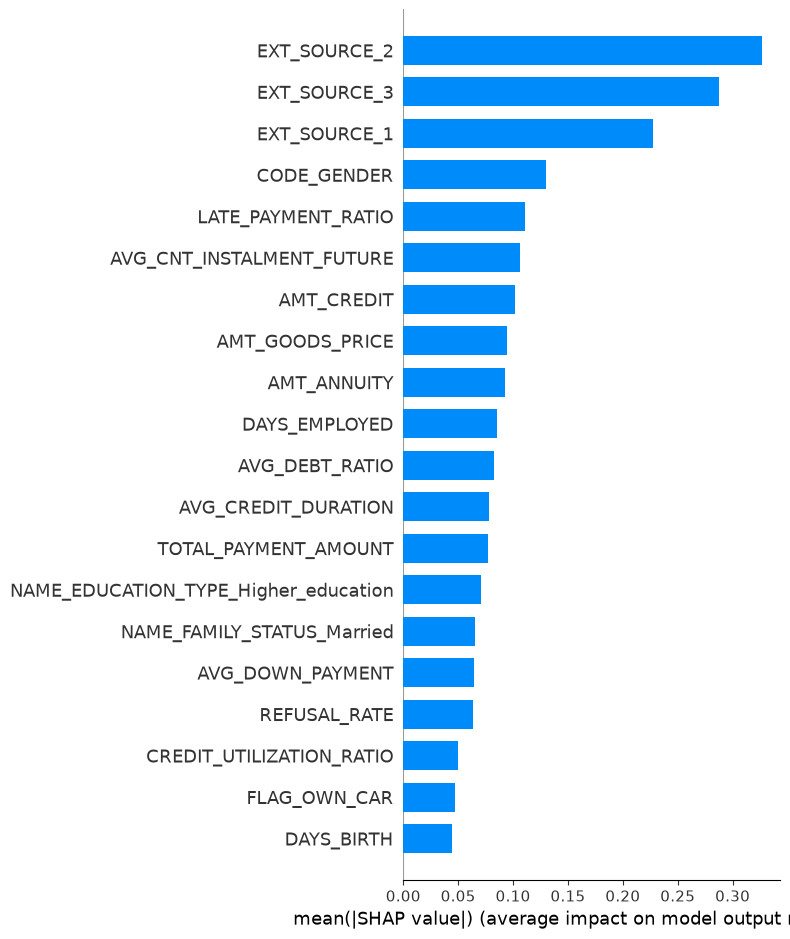

In [19]:
# IMPORTANCE GLOBALE DES VARIABLES

shap.summary_plot(
    shap_values_default,
    X_shap,
    plot_type="bar",
   
)

In [ ]:
# TABLEAU DES VARIABLES IMPORTANTES (influence moyenne de chaque variable : variation de defaut )

mean_abs_shap = np.abs(shap_values_default).mean(axis=0)

feature_importance_shap = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

feature_importance_shap = (
    feature_importance_shap
    .sort_values(
        by="Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_shap.head(20)

,Feature,Mean_Absolute_SHAP
0,EXT_SOURCE_2,0.326792
1,EXT_SOURCE_3,0.287389
2,EXT_SOURCE_1,0.227492
3,CODE_GENDER,0.130420
4,LATE_PAYMENT_RATIO,0.111092
5,AVG_CNT_INSTALMENT_FUTURE,0.105949
6,AMT_CREDIT,0.101924
7,AMT_GOODS_PRICE,0.094803
8,AMT_ANNUITY,0.093069
9,DAYS_EMPLOYED,0.084929


In [ ]:
# ============================================================
# SUMMARY PLOT SHAP
# ============================================================

shap.summary_plot(
    shap_values_default,
    X_shap,
    max_display=20
)

In [14]:
# ============================================================
# SAUVEGARDE DE L'IMPORTANCE SHAP
# ============================================================

feature_importance_shap.to_csv(
    "data/processed/shap_feature_importance.csv",
    index=False
)

print("Importance SHAP sauvegardée.")

Importance SHAP sauvegardée.


In [15]:
# ============================================================
# EXPLICATION INDIVIDUELLE D'UN CLIENT
# ============================================================

client_index = 0

print("Client analysé :", client_index)

print(
    "Probabilité de défaut :",
    model_lgb_spw.predict_proba(
        X_shap.iloc[[client_index]]
    )[0, 1]
)

Client analysé : 0
Probabilité de défaut : 0.369415854622972


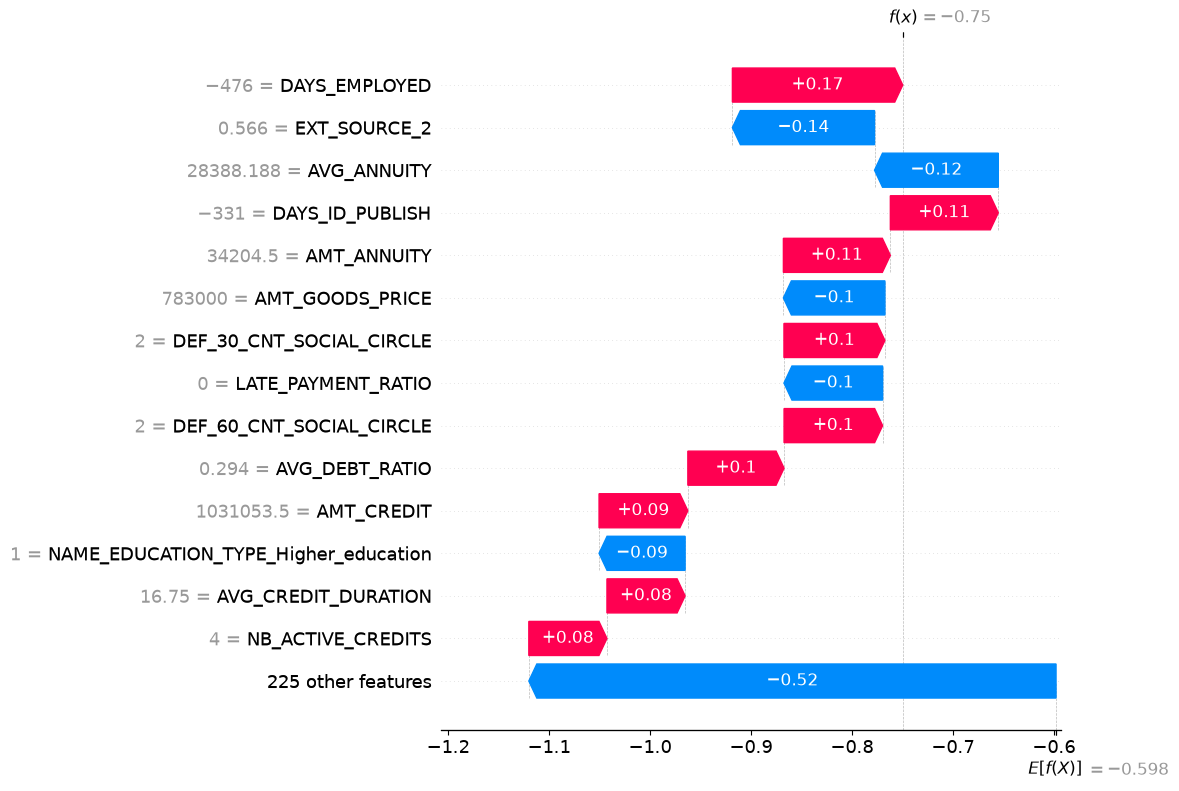

In [ ]:
# WATERFALL SHAP 

# Valeur de référence du modèle
if isinstance(explainer.expected_value, list):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

# Exclure CODE_GENDER uniquement du graphique
features_to_show = [
    i for i, col in enumerate(X_shap.columns)
    if col != "CODE_GENDER"
]

# Waterfall
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_default[client_index][features_to_show],
        base_values=base_value,
        data=X_shap.iloc[client_index].values[features_to_show],
        feature_names=X_shap.columns[features_to_show]
    ),
    max_display=15
)

In [ ]:
# ============================================================
# PROBABILITÉS DE DÉFAUT SUR L'ÉCHANTILLON SHAP
# ============================================================

proba_default = model_lgb_spw.predict_proba(X_shap)[:, 1]

print("Probabilité minimale :", proba_default.min())
print("Probabilité maximale :", proba_default.max())
print("Probabilité moyenne  :", proba_default.mean())

Probabilité minimale : 0.025995523493973858
Probabilité maximale : 0.9016859579616904
Probabilité moyenne  : 0.38028071319398205


In [ ]:
# ============================================================
# SÉLECTION DES CLIENTS EXTRÊMES
# ============================================================

client_low_risk = np.argmin(proba_default)
client_high_risk = np.argmax(proba_default)

print("Client faible risque :", client_low_risk)
print("Probabilité :", proba_default[client_low_risk])

print()

print("Client risque élevé :", client_high_risk)
print("Probabilité :", proba_default[client_high_risk])

Client faible risque : 59
Probabilité : 0.025995523493973858

Client risque élevé : 1844
Probabilité : 0.9016859579616904


Client faible risque : 59
Probabilité de défaut : 0.025995523493973858


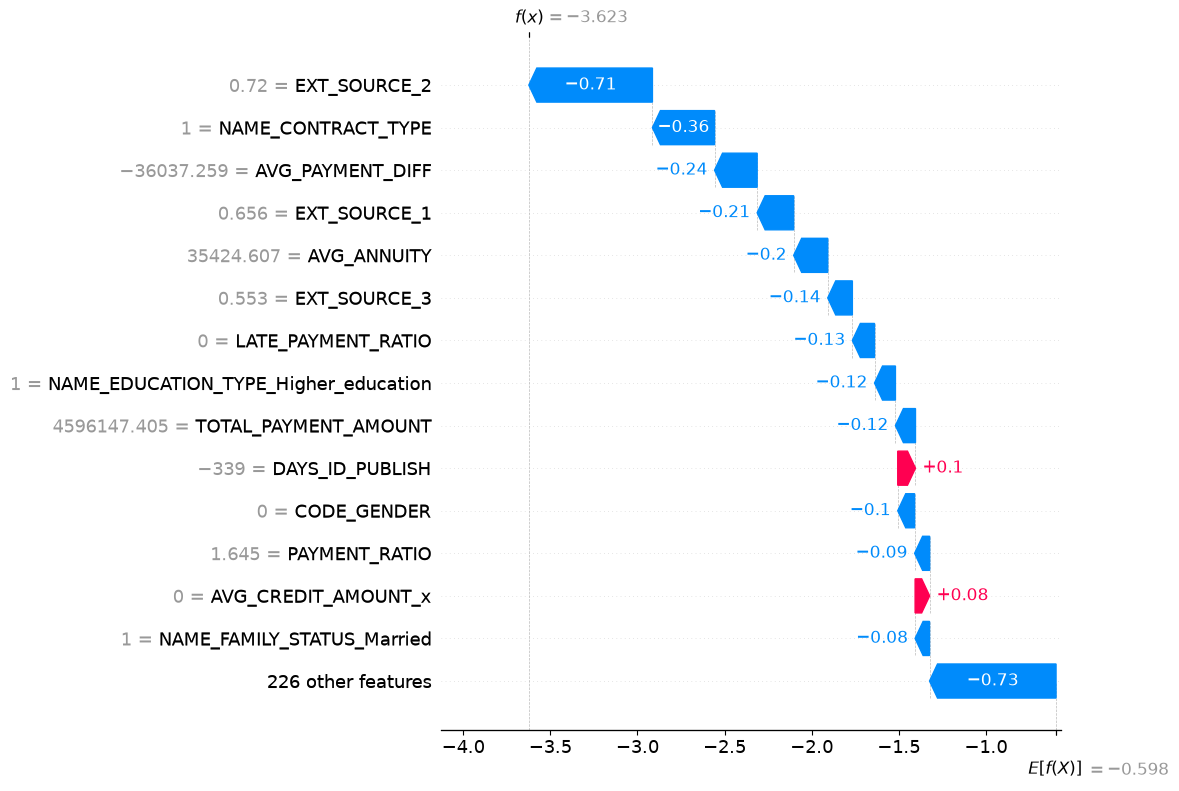

In [ ]:
# ============================================================
# WATERFALL — CLIENT À FAIBLE RISQUE
# ============================================================

client_index = client_low_risk

print("Client faible risque :", client_index)
print("Probabilité de défaut :", proba_default[client_index])

if isinstance(explainer.expected_value, list):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_default[client_index],
        base_values=base_value,
        data=X_shap.iloc[client_index],
        feature_names=X_shap.columns
    ),
    max_display=15
)

Client risque élevé : 1844
Probabilité de défaut : 0.9016859579616904


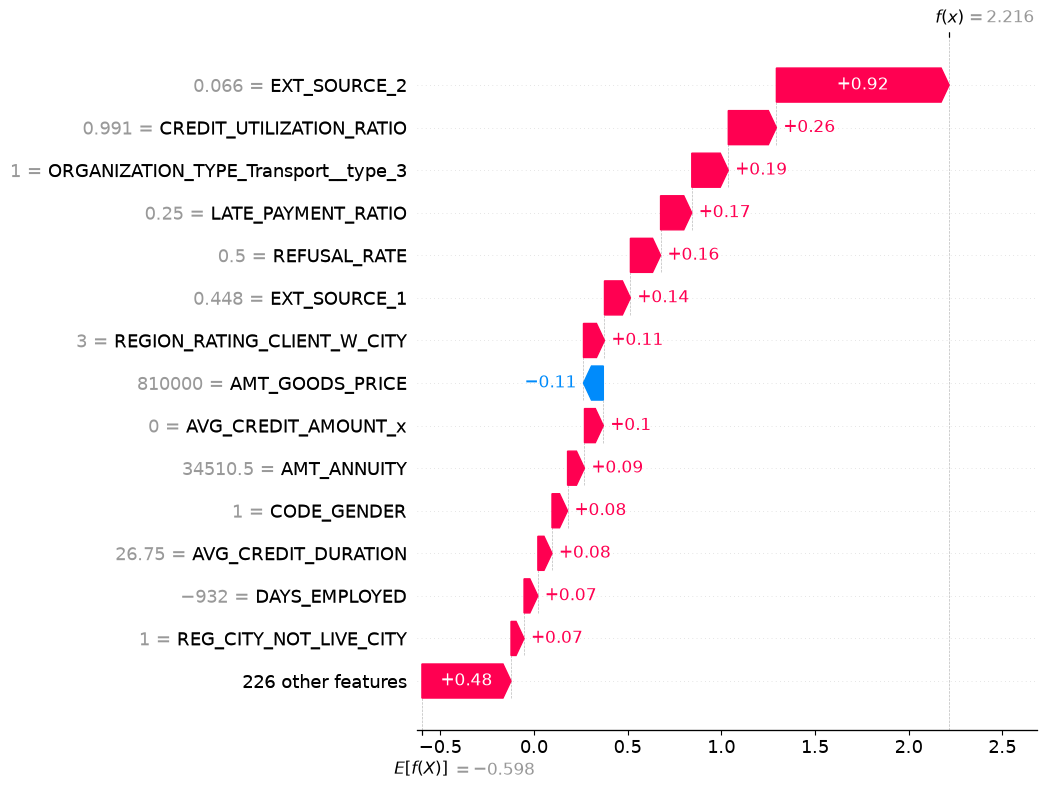

In [ ]:
# ============================================================
# WATERFALL — CLIENT À RISQUE ÉLEVÉ
# ============================================================

client_index = client_high_risk

print("Client risque élevé :", client_index)
print("Probabilité de défaut :", proba_default[client_index])

if isinstance(explainer.expected_value, list):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_default[client_index],
        base_values=base_value,
        data=X_shap.iloc[client_index],
        feature_names=X_shap.columns
    ),
    max_display=15
)

In [ ]:
# TABLEAU DÉTAILLÉ — CLIENT À RISQUE ÉLEVÉ

client_index = client_high_risk

client_shap = pd.DataFrame({
    "Feature": X_shap.columns,
    "Value": X_shap.iloc[client_index].values,
    "SHAP_Value": shap_values_default[client_index]
})

client_shap["Abs_SHAP"] = np.abs(client_shap["SHAP_Value"])

client_shap = (
    client_shap
    .sort_values("Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)

client_shap.head(15)

,Feature,Value,SHAP_Value,Abs_SHAP
0,EXT_SOURCE_2,0.065841,0.922137,0.922137
1,CREDIT_UTILIZATION_RATIO,0.990722,0.256700,0.256700
2,ORGANIZATION_TYPE_Transport__type_3,1.000000,0.194855,0.194855
3,LATE_PAYMENT_RATIO,0.250000,0.166601,0.166601
4,REFUSAL_RATE,0.500000,0.160989,0.160989
5,EXT_SOURCE_1,0.448080,0.138393,0.138393
6,REGION_RATING_CLIENT_W_CITY,3.000000,0.112129,0.112129
7,AMT_GOODS_PRICE,810000.000000,-0.106011,0.106011
8,AVG_CREDIT_AMOUNT_x,0.000000,0.100673,0.100673
9,AMT_ANNUITY,34510.500000,0.090212,0.090212


In [ ]:
# ============================================================
# TABLEAU DÉTAILLÉ — CLIENT À FAIBLE RISQUE
# ============================================================

client_index = client_low_risk

client_shap_low = pd.DataFrame({
    "Feature": X_shap.columns,
    "Value": X_shap.iloc[client_index].values,
    "SHAP_Value": shap_values_default[client_index]
})

client_shap_low["Abs_SHAP"] = np.abs(client_shap_low["SHAP_Value"])

client_shap_low = (
    client_shap_low
    .sort_values("Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)

client_shap_low.head(15)

,Feature,Value,SHAP_Value,Abs_SHAP
0,EXT_SOURCE_2,7.203892e-01,-0.709274,0.709274
1,NAME_CONTRACT_TYPE,1.000000e+00,-0.356486,0.356486
2,AVG_PAYMENT_DIFF,-3.603726e+04,-0.244523,0.244523
3,EXT_SOURCE_1,6.559057e-01,-0.209560,0.209560
4,AVG_ANNUITY,3.542461e+04,-0.195510,0.195510
5,EXT_SOURCE_3,5.531647e-01,-0.141369,0.141369
6,LATE_PAYMENT_RATIO,0.000000e+00,-0.127103,0.127103
7,NAME_EDUCATION_TYPE_Higher_education,1.000000e+00,-0.120029,0.120029
8,TOTAL_PAYMENT_AMOUNT,4.596147e+06,-0.115066,0.115066
9,DAYS_ID_PUBLISH,-3.390000e+02,0.101827,0.101827


In [ ]:
# SAUVEGARDE DU CLASSEMENT SHAP

feature_importance_shap.to_csv(
    "data/processed/shap_feature_importance.csv",
    index=False
)

print("✓ Classement SHAP sauvegardé.")

✓ Classement SHAP sauvegardé.


In [ ]:
# SAUVEGARDE DES SHAP VALUES

joblib.dump(
    shap_values_default,
    "data/processed/shap_values_default.pkl"
)

print("✓ SHAP values sauvegardées.")

✓ SHAP values sauvegardées.


In [ ]:
# SAUVEGARDE DE L'ÉCHANTILLON SHAP


X_shap.to_csv(
    "data/processed/X_shap_2000.csv",
    index=False
)

print("✓ Échantillon SHAP sauvegardé.")

✓ Échantillon SHAP sauvegardé.


In [ ]:

# SAUVEGARDE 

clients_shap = X_shap.iloc[[59, 1844]].copy()

clients_shap["SHAP_CASE"] = [
    "Faible risque",
    "Risque élevé"
]

clients_shap.to_csv(
    "data/processed/shap_clients_examples.csv",
    index=False
)

print("✓ Clients SHAP sauvegardés.")

✓ Clients SHAP sauvegardés.


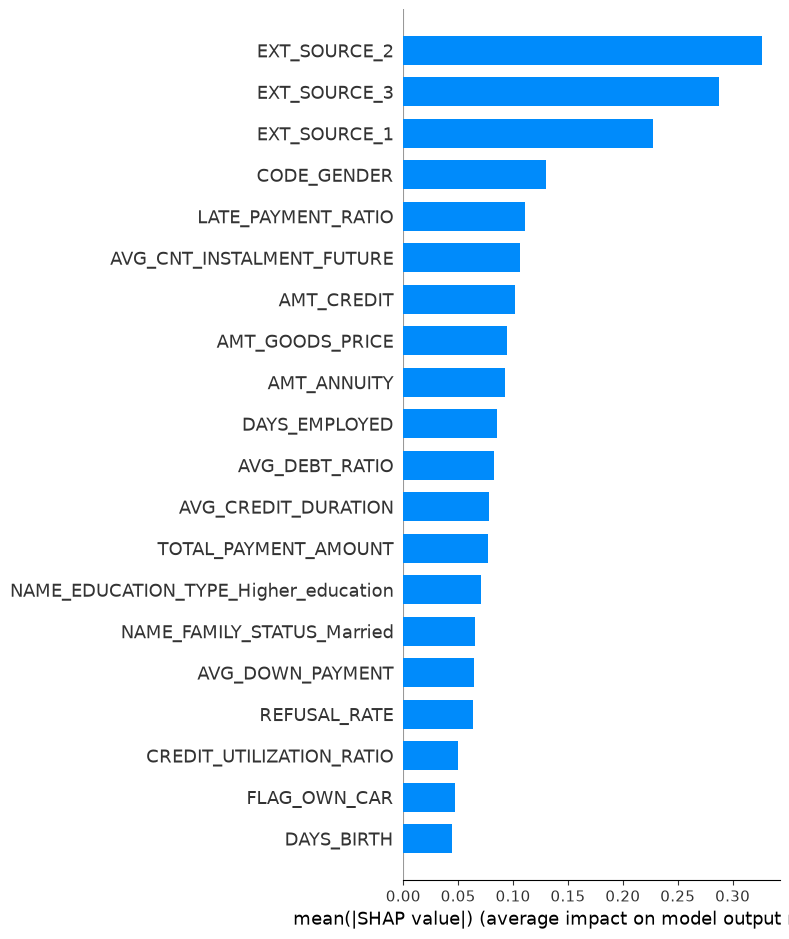

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

shap.summary_plot(
    shap_values_default,
    X_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.tight_layout()

plt.savefig(
    "data/processed/shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

In [ ]:
# ============================================================
# SAUVEGARDE DU WATERFALL SHAP - VERSION RAPIDE
# ============================================================

import matplotlib.pyplot as plt

plt.savefig(
    "data/processed/shap_waterfall_high_risk.png",
    dpi=150,
    bbox_inches="tight"
)

plt.close()

print("✅ Graphique SHAP sauvegardé avec succès.")

✅ Graphique SHAP sauvegardé avec succès.


In [ ]:
import os

path = "data/processed/shap_waterfall_high_risk.png"

print("Existe :", os.path.exists(path))

if os.path.exists(path):
    print("Taille :", os.path.getsize(path) / 1024, "KB")

Existe : True
Taille : 138.578125 KB


In [ ]:
import pandas as pd

df_shap = pd.read_csv(
    "data/processed/shap_feature_importance.csv"
)

print(df_shap.shape)
print(df_shap.columns.tolist())
print(df_shap.head(10))

(240, 2)
['Feature', 'Mean_Absolute_SHAP']
                     Feature  Mean_Absolute_SHAP
0               EXT_SOURCE_2            0.326792
1               EXT_SOURCE_3            0.287389
2               EXT_SOURCE_1            0.227492
3                CODE_GENDER            0.130420
4         LATE_PAYMENT_RATIO            0.111092
5  AVG_CNT_INSTALMENT_FUTURE            0.105949
6                 AMT_CREDIT            0.101924
7            AMT_GOODS_PRICE            0.094803
8                AMT_ANNUITY            0.093069
9              DAYS_EMPLOYED            0.084929
